# Australian unemployment: time-series anatomy

I am starting with a single monthly economic series before I touch forecasting models.

The unemployment rate is a useful first case because it has a long history, obvious persistence, structural shifts and some sharp shocks. I want to understand what the series looks like in levels and changes, what its autocorrelation structure is doing, and what a sensible holdout period should look like.

I am deliberately not fitting a forecasting model yet.


## Source

I am using the Reserve Bank of Australia's H5 Labour Force table and the seasonally adjusted unemployment-rate series `GLFSURSA`.

I am pulling the CSV directly from the RBA so the notebook records how the data was obtained rather than relying on a copied local file.


In [33]:
from __future__ import annotations

import csv
import io
import warnings
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

RBA_H5_URL = "https://www.rba.gov.au/statistics/tables/csv/h5-data.csv"
SERIES_ID = "GLFSURSA"


In [34]:
def read_rba_csv(url: str):
    with urllib.request.urlopen(url) as response:
        text = response.read().decode("utf-8-sig")

    rows = list(csv.reader(io.StringIO(text)))

    header_rows = [
        i
        for i, row in enumerate(rows)
        if row and row[0].strip() == "Series ID" and len(row) > 1
    ]

    if not header_rows:
        raise ValueError("Could not find the RBA Series ID header.")

    header_row = header_rows[-1]
    header = rows[header_row]

    # Remove completely blank physical rows from the RBA CSV.
    data_rows = [
        row
        for row in rows[header_row + 1 :]
        if row and any(field.strip() for field in row)
    ]

    raw = pd.DataFrame(data_rows, columns=header)

    return raw, rows[:header_row]


raw, metadata = read_rba_csv(RBA_H5_URL)

raw.head()


,Series ID,GLFSLFSA,GLFSPRSA,GLFSEPPSA,GLFSEPFSA,GLFSEPTSA,GLFSEPTSYP,GLFSEPTTYP,GLFSEPTPOP,GLFSUPSA,GLFSURSA,GLFSURTR,GLFMHW,GLFMHWTR,GLFMHWTRYP,GLFMHWAV,GLFOSVT,GLFOSVPS,GLFOSVTLF
0,28/02/1978,6424.3,61.2,918.1,5079.3,5997.4,,,57.2,426.9,6.6,6.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31/03/1978,6406.7,61.0,907.8,5095.1,6002.9,,,57.1,403.8,6.3,6.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,30/04/1978,6433.9,61.2,911.2,5119.5,6030.7,,,57.3,403.2,6.3,6.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,31/05/1978,6432.5,61.1,914.3,5118.7,6033.1,,,57.3,399.4,6.2,6.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,30/06/1978,6439.8,61.1,929.7,5104.1,6033.8,,,57.2,406.0,6.3,6.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Build the monthly series

Assuming unique monthly dates in chronological order, numeric values, and no silent gaps (check this assumption).


In [35]:
if SERIES_ID not in raw.columns:
    raise KeyError(f"{SERIES_ID} was not found in the RBA table.")

unemployment = raw[["Series ID", SERIES_ID]].copy()

unemployment.columns = [
    "period",
    "unemployment_rate",
]

rows_before_cleaning = len(unemployment)


# -------------------------------------------------------------------
# Parse and validate dates
# -------------------------------------------------------------------

parsed_dates = pd.to_datetime(
    unemployment["period"],
    format="%d/%m/%Y",
    errors="coerce",
)

invalid_dates = parsed_dates.isna()

if invalid_dates.any():
    examples = (
        unemployment.loc[invalid_dates, "period"]
        .head()
        .tolist()
    )

    raise ValueError(
        f"Found {invalid_dates.sum()} invalid RBA dates. "
        f"Examples: {examples}"
    )


# The RBA records observations at month end.
# Normalise to month start because the notebook uses monthly frequency "MS".
unemployment["date"] = (
    parsed_dates
    .dt.to_period("M")
    .dt.to_timestamp()
)


# -------------------------------------------------------------------
# Parse and validate unemployment values
# -------------------------------------------------------------------

rate_text = (
    unemployment["unemployment_rate"]
    .astype("string")
    .str.strip()
)

nonblank_rate = rate_text.notna() & rate_text.ne("")

unemployment["unemployment_rate"] = pd.to_numeric(
    rate_text,
    errors="coerce",
)


# A nonblank value that cannot be converted to numeric is a source/schema
# problem and should not be silently discarded.
non_numeric = (
    nonblank_rate
    & unemployment["unemployment_rate"].isna()
)

if non_numeric.any():
    examples = (
        unemployment.loc[
            non_numeric,
            ["period", "unemployment_rate"],
        ]
        .head()
    )

    raise ValueError(
        "Found non-numeric unemployment values:\n"
        + examples.to_string(index=False)
    )


# Blank values are allowed only after the final observed value.
missing_values = unemployment["unemployment_rate"].isna()

last_observed_date = unemployment.loc[
    ~missing_values,
    "date",
].max()

unexpected_missing = (
    missing_values
    & unemployment["date"].le(last_observed_date)
)

if unexpected_missing.any():
    examples = (
        unemployment.loc[
            unexpected_missing,
            ["period", "unemployment_rate"],
        ]
        .head()
    )

    raise ValueError(
        "Missing unemployment values occur inside the observed history:\n"
        + examples.to_string(index=False)
    )


# -------------------------------------------------------------------
# Keep actual observations
# -------------------------------------------------------------------

print(f"Rows before cleaning: {rows_before_cleaning}")
print(f"Rows with invalid dates: {invalid_dates.sum()}")
print(
    "Future placeholder rows without unemployment values: "
    f"{missing_values.sum()}"
)

unemployment = (
    unemployment.loc[
        ~missing_values,
        ["date", "unemployment_rate"],
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

rows_after_cleaning = len(unemployment)

print(f"Rows after cleaning: {rows_after_cleaning}")
print(
    f"Rows removed: "
    f"{rows_before_cleaning - rows_after_cleaning}"
)


# -------------------------------------------------------------------
# Validate time-series structure
# -------------------------------------------------------------------

assert unemployment["date"].is_unique
assert unemployment["date"].is_monotonic_increasing

expected_dates = pd.date_range(
    unemployment["date"].min(),
    unemployment["date"].max(),
    freq="MS",
)

missing_dates = expected_dates.difference(
    unemployment["date"]
)

print(f"First observation: {unemployment['date'].min().date()}")
print(f"Last observation:  {unemployment['date'].max().date()}")
print(f"Observations:       {len(unemployment)}")
print(f"Missing months:     {len(missing_dates)}")

Rows before cleaning: 585
Rows with invalid dates: 0
Future placeholder rows without unemployment values: 3
Rows after cleaning: 582
Rows removed: 3
First observation: 1978-02-01
Last observation:  2026-07-01
Observations:       582
Missing months:     0


## First look at the level

I am looking for persistence, turning points, long-run shifts, abrupt shocks and changes in volatility.


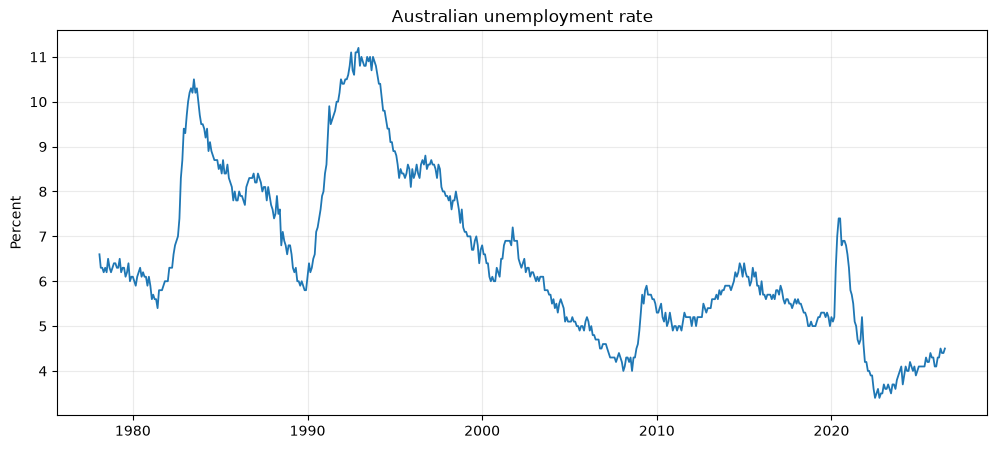

In [36]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(unemployment["date"], unemployment["unemployment_rate"], linewidth=1.3)
ax.set(title="Australian unemployment rate", xlabel="", ylabel="Percent")
ax.grid(alpha=0.25)
plt.show()


### Initial notes

- Early 80's spike in unemployment was due to the global oil shocks and led to stagflation and low economic demand, increasing unemployment.
- From 1984 to 1990, Australia led the OECD in economic growth. The Hawke-Keating governments' **Prices and Incomes Accord** restrained wage increases, lowering real unit labour costs and making it cheaper for businesses to hire workers, decreasing unemployment.
- Unemployment increased quickly in the 1990-91 "Recession we had to have". The RBA under the Keating government increased the cash rate to 18%; this took longer than expected to cool the economy, fuelled in part by real estate speculation and global factors. This ultimately led to the collapse of the State Bank of Victoria and the State Bank of South Australia.
- Australia enjoyed a long period of growth from the early 90s until 2008 due to the mining boom, structural reforms including tariff reductions, financial market deregulation and an increase in part-time work.
- In 2008, the GFC cooled economic conditions, increasing unemployment.
- Unemployment remained stable between 5 and 6% for the 2010's. This was a period of flexible monetary policy, with the RBA gradually easing interest rates. Large-scale infrastructure projects such as the NBN rollout and a continued movement towards part-time and casual jobs allowed employers to adjust hours rather than terminate employees. This was also a period of relatively high immigration, fueling sustained economic demand.
- Unemployment spiked during COVID and has decreased post-COVID due to post-pandemic-era fiscal stimulus (like the $90 billion JobKeeper payment), quantitative easing, and a temporary freeze on international migration.  
- There is a suggestion of an 8-12-year cycle in unemployment


## Levels and changes

The rate of change seems to be dominated by sudden, sharp increases in unemployment followed by steady periods of decreasing unemployment. I want to see how much of that persistence remains after first differencing.

The monthly change is simply `y[t] - y[t-1]`.


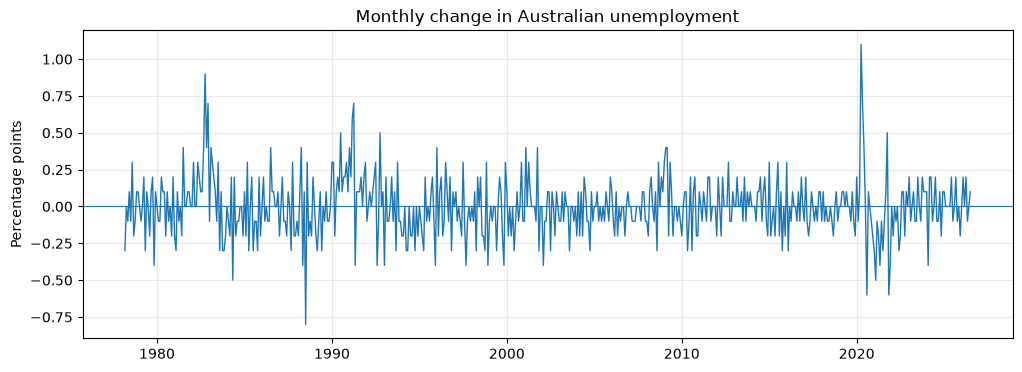

In [37]:
unemployment["monthly_change"] = unemployment["unemployment_rate"].diff()
unemployment["annual_change"] = unemployment["unemployment_rate"].diff(12)

fig, ax = plt.subplots(figsize=(12, 4))
ax.axhline(0, linewidth=0.8)
ax.plot(unemployment["date"], unemployment["monthly_change"], linewidth=1)
ax.set(
    title="Monthly change in Australian unemployment",
    xlabel="",
    ylabel="Percentage points",
)
ax.grid(alpha=0.25)
plt.show()


### Notes on the differenced series

- Outside of recessions and global pandemics, the rate of change in unemployment is rarely more than +_ 0.3% per month 
- Recessions have a much more dramatic impact on the rate of change of unemployment, with the rate of change approaching or exceeding 1% per month. These are structural breaks in the economy.  


## Autocorrelation

This is where the temporal structure should become obvious. I want to compare the level with monthly changes rather than looking at the level alone.


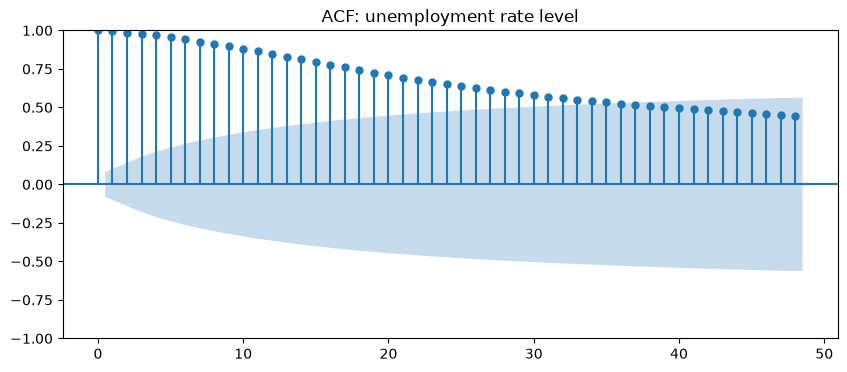

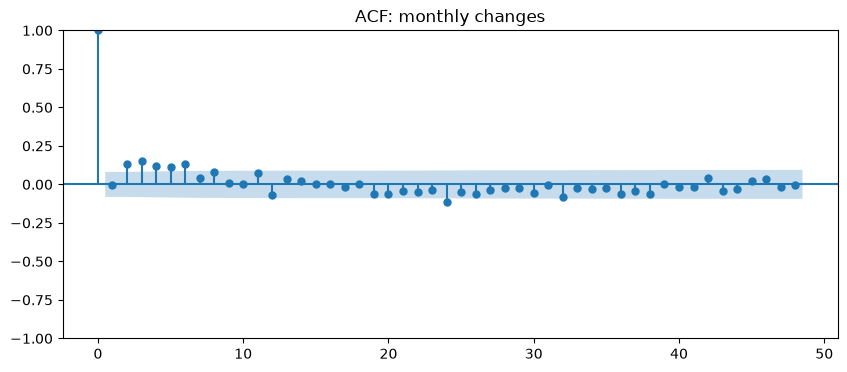

In [38]:
level = unemployment["unemployment_rate"].dropna()
change = unemployment["monthly_change"].dropna()

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(level, lags=48, ax=ax)
ax.set_title("ACF: unemployment rate level")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(change, lags=48, ax=ax)
ax.set_title("ACF: monthly changes")
plt.show()


### My read of the ACF

- ACF is a measure or plot of statistical dependence as a function of the time distance (lag) between pairs of observations, similar to a variogram in spatial statistics
- There is a negative sigmoidal ACF showing a strong positive correlation out to about 30 months.
- The ACF of the rate of change of unemployment is significant out to about 10 months and negative or close to zero beyond that time frame. 
- Further reading: https://apxml.com/courses/time-series-analysis-forecasting/chapter-3-autocorrelation-model-id
- Lag of ACF of the First Difference is effectively 0. The first difference becomes stationary imediatly 


## Partial autocorrelation

I am not selecting an AR model yet. I mainly want to start recognising what direct lag relationships look like before getting to ARIMA.


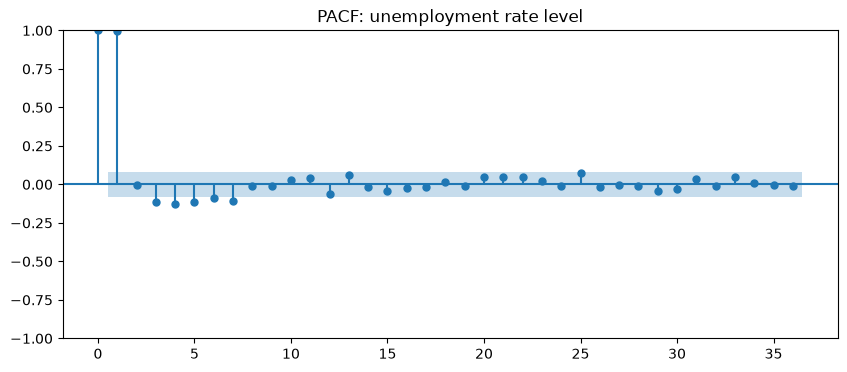

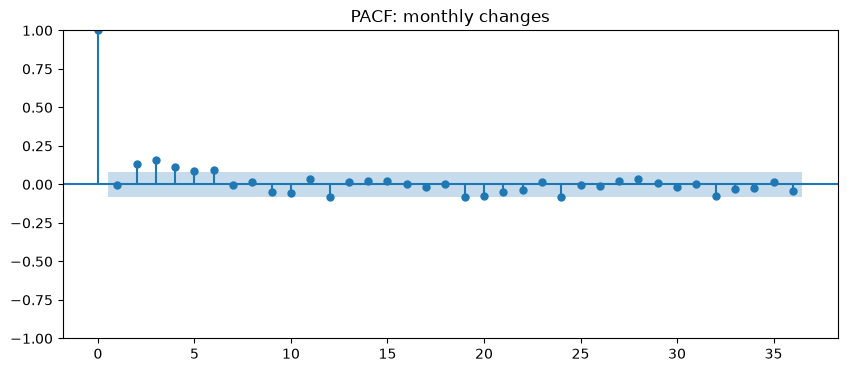

In [39]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(level, lags=36, method="ywm", ax=ax)
ax.set_title("PACF: unemployment rate level")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(change, lags=36, method="ywm", ax=ax)
ax.set_title("PACF: monthly changes")
plt.show()


## Stationarity checks

I am using both ADF and KPSS because their null hypotheses run in opposite directions.

I do not want to turn these into an automatic stationary/not-stationary label. Structural breaks and regime changes can make that too simplistic.


In [40]:
def stationarity_summary(series: pd.Series) -> pd.Series:
    x = series.dropna()
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        adf = adfuller(x, autolag="AIC", result_object=True)
        kpss_result = kpss(x, regression="c", nlags="auto", result_object=True)
        
    return pd.Series({
        "ADF statistic": adf[0],
        "ADF p-value": adf[1],
        "KPSS statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1],
    })

pd.DataFrame({
    "level": stationarity_summary(unemployment["unemployment_rate"]),
    "monthly_change": stationarity_summary(unemployment["monthly_change"]),
})


,level,monthly_change
ADF statistic,-2.260404,-6.500784e+00
ADF p-value,0.185057,1.163302e-08
KPSS statistic,1.841440,7.029238e-02
KPSS p-value,0.010000,1.000000e-01


### My interpretation

- This is the textbook PACF signature of an AR(1)-like process on a near-unit-root series: once you control for the value one month ago, no other lag adds meaningful direct information. 
- The slow ACF decay plus a sharp PACF cutoff at lag 1 is the classic pattern for a highly persistent, near-random-walk level series. It shows that the unemployment level is driven almost entirely by inertia from the previous month, not by some more complex multi-lag structure
- Differencing has removed almost all the strong autocorrelation
- We are trying to find what model is the best fit for our data; candidates include Moving Average (MA), Autoregressive (AR), a mix ARMA or possible Autoregressive integrated moving average (ARIMA)
- ARIMA assumes a stationary (non-trending) series. Differencing usually reduces a series to a stationary series; if not, a second difference may need to be applied. The number of times you need to difference to achieve a stationary series is known as the order of integration 'd' in the ARIMA(p,d,q) model
- If the ACF declines quickly to 0 and the PACF has significant spikes, then that sugests an AR(p) model
- If the ACF has significant spikes and the PACF declines quickly to 0, then a MA(q) is a better model 


references: 
https://people.duke.edu/~rnau/Notes_on_nonseasonal_ARIMA_models--Robert_Nau.pdf
https://people.duke.edu/~rnau/411home.htm
https://online.stat.psu.edu/stat510/
https://www.youtube.com/@mydataanalysissite878/videos in particular https://www.youtube.com/watch?v=TwL3gm8MYyk
https://otexts.com/fpp3/ - Forecasting: Principles and Practice (3rd ed)


## STL decomposition

STL (Seasonal-Trend decomposition using Loess) splits a time series into three additive pieces:
**observed=trend+seasonal+residual**

The series is already seasonally adjusted. I am using STL as a diagnostic to see how much repeating 12-month structure remains after the official adjustment.


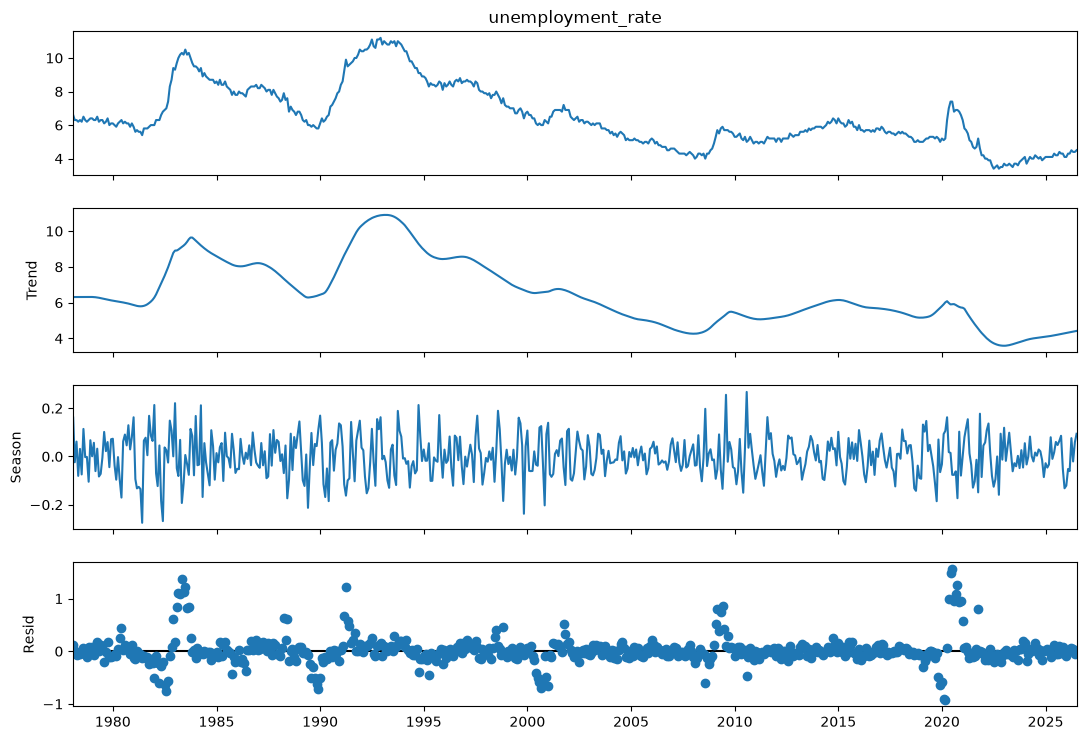

In [41]:
monthly = unemployment.set_index("date")["unemployment_rate"].asfreq("MS").dropna()
stl = STL(monthly, period=12, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(12, 8)
plt.show()


### Notes on STL

- Panel 1 is the raw seasonally adjusted unemployment rate
- The trend shows multi-year swings up during recessions and down during expansions, stripped of month-to-month noise.
- The seasonal trend should be flat; this is telling us that the RBA data still shows artifacts of seasonality. The periods of greatest variation somewhat align with the peaks and troughs of unemployment, signalling that the seasonal component is somewhat entangled with volatility/residual,
- There's residual seasonality left over during the peaks and troughs in the unemployment rate, COVID, GFC and the twin recessions. 


## Temporal holdout

A random train/test split would be wrong for forecasting because it would let future observations influence the training sample.

For now I am holding out the most recent five years. This is only a first cut; Chapter 02 will replace this with rolling-origin evaluation.


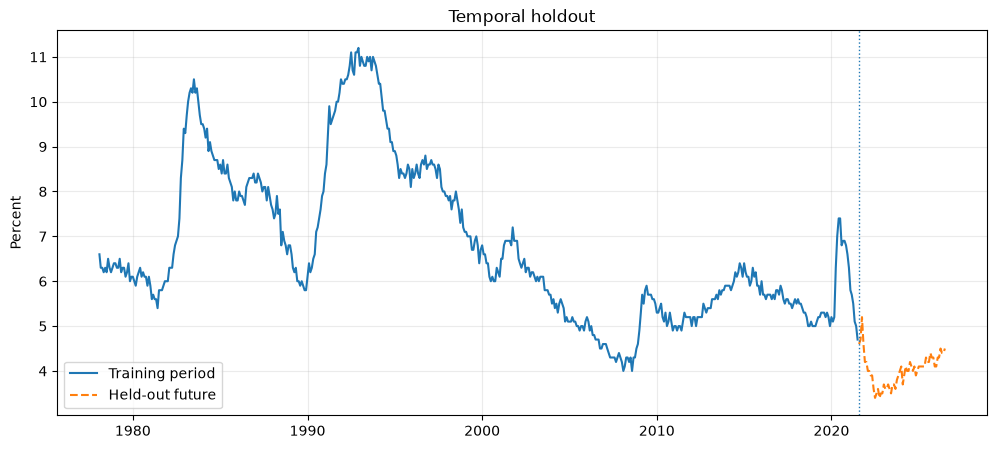

In [42]:
HOLDOUT_MONTHS = 60

train = unemployment.iloc[:-HOLDOUT_MONTHS].copy()
test = unemployment.iloc[-HOLDOUT_MONTHS:].copy()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train["date"], train["unemployment_rate"], label="Training period")
ax.plot(test["date"], test["unemployment_rate"], linestyle="--", label="Held-out future")
ax.axvline(test["date"].iloc[0], linestyle=":", linewidth=1)
ax.set(title="Temporal holdout", xlabel="", ylabel="Percent")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## Notes



- **Persistence:**
      ACF Lag of 35, so non stationary 
- **Effect of differencing:**
      1st difference lag is efectivly 0
- **Structural shocks / breaks:**
      Structural breaks associated with pandemics and recessions appear as peaks and troughs, and longterm changes in slope are highlighted in the residuals but do not show a periodicity at the scale of this data  
- **Stationarity:** 
- **Residual seasonality:** 
- **Likely modelling difficulties:** 
- **What simple baselines may do well:** 
- **What a more complex model might plausibly add:** 




## Save the processed series

The processed file stays outside Git. The notebook records the transformation so I can recreate it from the RBA source.


In [43]:
output = Path("data/processed/rba_h5_unemployment_sa.parquet")
output.parent.mkdir(parents=True, exist_ok=True)
unemployment.to_parquet(output, index=False)
print(f"Wrote {len(unemployment):,} rows to {output}")


Wrote 582 rows to data/processed/rba_h5_unemployment_sa.parquet


## Next

Next I will use this same series to build the baseline forecast harness:

- mean;
- naïve;
- seasonal naïve;
- drift;
- rolling-origin evaluation;
- MAE, RMSE and MASE;
- error by forecast horizon.

That becomes the benchmark every later model has to beat, including ARIMA, LSTM and TimesFM.
